# Homework 6.1 - Steps 2-3

## Lorenz Data, Tokenization, and Markov Baseline

This notebook is the computational continuation of Step 1.

The workflow is

$$
\text{Lorenz trajectories}
\longrightarrow
\text{phase-space boxes}
\longrightarrow
\text{token books}
\longrightarrow
\text{Markov / m-gram baseline}.
$$

The same Lorenz system is used as in Homework 5.2:

$$
\dot{x}=10(y-x),
$$

$$
\dot{y}=x(28-z)-y,
$$

$$
\dot{z}=xy-\frac{8}{3}z.
$$

The purpose of reproducing the data pipeline here is to make Homework 6.1 self-contained while keeping the dynamical system, sampling scheme, and baseline discretization fixed for a fair comparison with attention.

## Experimental protocol

The design is fixed before model fitting:

- 40 training trajectories;
- 10 validation trajectories;
- 10 test trajectories;
- independent seeded initial conditions;
- 5 time units discarded as transient;
- 25 time units retained;
- fixed sampling interval

$$
\Delta t=0.02;
$$

- baseline discretization

$$
12\times12\times12.
$$

The phase-space bounds are fitted from the **training trajectories only** and expanded by a fixed 5% margin.

No context or transition is allowed to cross a trajectory-book boundary.

In [27]:
from pathlib import Path
from collections import Counter, defaultdict
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw6_1"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw6_1"

TRAJECTORY_DIR = DATA_DIR / "trajectories"
TOKEN_DIR = DATA_DIR / "token_books"

for path in [
    DATA_DIR,
    RESULT_DIR,
    TRAJECTORY_DIR / "train",
    TRAJECTORY_DIR / "validation",
    TRAJECTORY_DIR / "test",
    TOKEN_DIR / "train",
    TOKEN_DIR / "validation",
    TOKEN_DIR / "test",
]:
    path.mkdir(parents=True, exist_ok=True)

SEED = 63861

SIGMA = 10.0
RHO = 28.0
BETA = 8.0 / 3.0

N_TRAIN = 40
N_VALIDATION = 10
N_TEST = 10

TRANSIENT_TIME = 5.0
RECORD_TIME = 25.0
DT = 0.02

BASELINE_BINS = (12, 12, 12)
BOUND_PADDING_FRACTION = 0.05

rng = np.random.default_rng(SEED)

print("Project root:", PROJECT_ROOT.resolve())
print("Data folder:", DATA_DIR.resolve())
print("Result image folder:", RESULT_DIR.resolve())

Project root: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1
Data folder: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\data\hw6_1
Result image folder: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\result images\hw6_1


# Task 1 computational continuation: generate trajectory books

Each independently simulated trajectory is one book.

Initial conditions are sampled from

$$
x_0,y_0\in[-20,20],
\qquad
z_0\in[5,35].
$$

The train/validation/test assignment is fixed before discretization or model fitting.

In [28]:
def lorenz_rhs(t, state):
    x, y, z = state

    dx = SIGMA * (y - x)
    dy = x * (RHO - z) - y
    dz = x * y - BETA * z

    return np.array([dx, dy, dz], dtype=float)


def draw_initial_condition(rng):
    return np.array([
        rng.uniform(-20.0, 20.0),
        rng.uniform(-20.0, 20.0),
        rng.uniform(5.0, 35.0),
    ], dtype=float)


def simulate_trajectory(initial_condition):
    total_time = TRANSIENT_TIME + RECORD_TIME

    t_eval = np.arange(
        0.0,
        total_time + 0.5 * DT,
        DT,
    )

    solution = solve_ivp(
        lorenz_rhs,
        (0.0, total_time),
        initial_condition,
        t_eval=t_eval,
        method="DOP853",
        rtol=1e-9,
        atol=1e-11,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    keep = solution.t >= TRANSIENT_TIME - 1e-12

    time = solution.t[keep] - TRANSIENT_TIME
    states = solution.y[:, keep].T

    return time, states


split_sizes = {
    "train": N_TRAIN,
    "validation": N_VALIDATION,
    "test": N_TEST,
}

manifest_rows = []
global_book_id = 0

for split_name, count in split_sizes.items():
    for book_index in range(count):
        initial_condition = draw_initial_condition(rng)
        time, states = simulate_trajectory(initial_condition)

        output_path = (
            TRAJECTORY_DIR
            / split_name
            / f"book_{book_index:03d}.npz"
        )

        np.savez_compressed(
            output_path,
            time=time,
            states=states,
            initial_condition=initial_condition,
        )

        manifest_rows.append({
            "global_book_id": global_book_id,
            "split": split_name,
            "book": book_index,
            "samples": len(time),
            "initial_x": initial_condition[0],
            "initial_y": initial_condition[1],
            "initial_z": initial_condition[2],
            "file": str(output_path.relative_to(PROJECT_ROOT)),
        })

        global_book_id += 1

trajectory_manifest = pd.DataFrame(manifest_rows)

manifest_path = DATA_DIR / "trajectory_manifest.csv"
trajectory_manifest.to_csv(manifest_path, index=False)

print(
    trajectory_manifest.groupby("split")["samples"]
    .agg(["count", "min", "max"])
)

print()
print("Saved:", manifest_path.resolve())

            count   min   max
split                        
test           10  1251  1251
train          40  1251  1251
validation     10  1251  1251

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\data\hw6_1\trajectory_manifest.csv


## Visual trajectory check

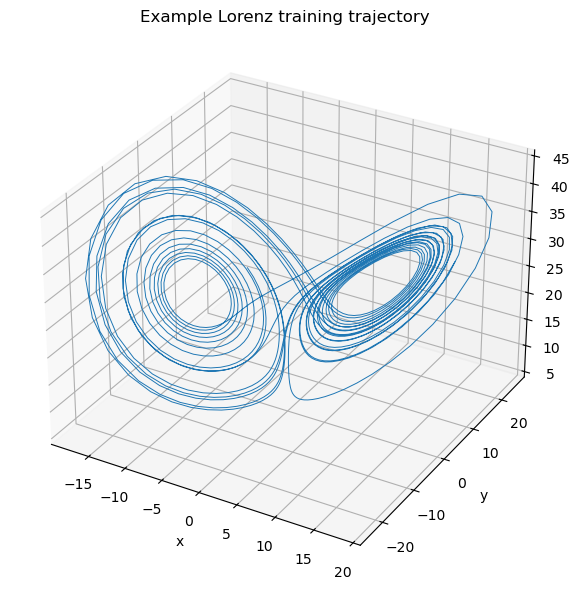

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\result images\hw6_1\step1_example_lorenz_3d.png


In [29]:
example = np.load(
    TRAJECTORY_DIR / "train" / "book_000.npz"
)

states = example["states"]

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot(
    states[:, 0],
    states[:, 1],
    states[:, 2],
    linewidth=0.7,
)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Example Lorenz training trajectory")
plt.tight_layout()

path = RESULT_DIR / "step1_example_lorenz_3d.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", path.resolve())

# Task 2: discretize phase space and construct token sequences

The baseline phase-space grid uses

$$
N_x=N_y=N_z=12.
$$

Thus the number of possible tokens is

$$
|\mathcal V_{\text{possible}}|
=
12^3
=
1728.
$$

The training trajectories alone determine the physical lower and upper bounds of the grid.

In [30]:
def load_state_books(split_name):
    books = []

    for path in sorted(
        (TRAJECTORY_DIR / split_name).glob("book_*.npz")
    ):
        data = np.load(path)
        books.append(data["states"])

    return books


train_state_books = load_state_books("train")

training_cloud = np.vstack(train_state_books)

raw_min = training_cloud.min(axis=0)
raw_max = training_cloud.max(axis=0)
span = raw_max - raw_min

lower_bounds = raw_min - BOUND_PADDING_FRACTION * span
upper_bounds = raw_max + BOUND_PADDING_FRACTION * span

nx, ny, nz = BASELINE_BINS

x_edges = np.linspace(lower_bounds[0], upper_bounds[0], nx + 1)
y_edges = np.linspace(lower_bounds[1], upper_bounds[1], ny + 1)
z_edges = np.linspace(lower_bounds[2], upper_bounds[2], nz + 1)

print("Training-fitted lower bounds:", lower_bounds)
print("Training-fitted upper bounds:", upper_bounds)
print("Possible vocabulary size:", nx * ny * nz)

Training-fitted lower bounds: [-2.09512019e+01 -2.87294153e+01 -2.52458399e-02]
Training-fitted upper bounds: [21.06982345 29.04814633 49.31562746]
Possible vocabulary size: 1728


In [31]:
def coordinate_to_bin(values, edges):
    raw = np.searchsorted(
        edges,
        values,
        side="right",
    ) - 1

    outside = (
        (values < edges[0])
        | (values > edges[-1])
    )

    indices = np.clip(
        raw,
        0,
        len(edges) - 2,
    ).astype(int)

    return indices, outside


def states_to_tokens(states):
    ix, out_x = coordinate_to_bin(states[:, 0], x_edges)
    iy, out_y = coordinate_to_bin(states[:, 1], y_edges)
    iz, out_z = coordinate_to_bin(states[:, 2], z_edges)

    tokens = (
        ix * (ny * nz)
        + iy * nz
        + iz
    ).astype(np.int64)

    clipped = out_x | out_y | out_z

    return tokens, ix, iy, iz, clipped


def token_to_indices(token):
    ix = token // (ny * nz)
    remainder = token % (ny * nz)
    iy = remainder // nz
    iz = remainder % nz
    return ix, iy, iz


def token_center(token):
    ix, iy, iz = token_to_indices(int(token))

    return np.array([
        0.5 * (x_edges[ix] + x_edges[ix + 1]),
        0.5 * (y_edges[iy] + y_edges[iy + 1]),
        0.5 * (z_edges[iz] + z_edges[iz + 1]),
    ])

In [32]:
token_manifest_rows = []
all_tokens_by_split = {
    "train": [],
    "validation": [],
    "test": [],
}

for split_name, count in split_sizes.items():
    for book_index in range(count):
        trajectory = np.load(
            TRAJECTORY_DIR
            / split_name
            / f"book_{book_index:03d}.npz"
        )

        time = trajectory["time"]
        states = trajectory["states"]

        tokens, ix, iy, iz, clipped = states_to_tokens(states)

        output_path = (
            TOKEN_DIR
            / split_name
            / f"book_{book_index:03d}.csv"
        )

        pd.DataFrame({
            "sample_index": np.arange(len(tokens)),
            "time": time,
            "token": tokens,
            "ix": ix,
            "iy": iy,
            "iz": iz,
            "clipped_to_training_bounds": clipped,
        }).to_csv(output_path, index=False)

        all_tokens_by_split[split_name].append(tokens)

        token_manifest_rows.append({
            "split": split_name,
            "book": book_index,
            "samples": len(tokens),
            "distinct_tokens": len(np.unique(tokens)),
            "clipped_samples": int(clipped.sum()),
            "clipped_fraction": float(clipped.mean()),
            "file": str(output_path.relative_to(PROJECT_ROOT)),
        })

token_manifest = pd.DataFrame(token_manifest_rows)

token_manifest_path = DATA_DIR / "token_book_manifest.csv"
token_manifest.to_csv(token_manifest_path, index=False)

print(
    token_manifest.groupby("split")[
        ["samples", "distinct_tokens", "clipped_samples"]
    ].agg({
        "samples": ["count", "sum"],
        "distinct_tokens": ["min", "max"],
        "clipped_samples": "sum",
    })
)

print()
print("Saved:", token_manifest_path.resolve())

           samples        distinct_tokens      clipped_samples
             count    sum             min  max             sum
split                                                         
test            10  12510             122  179               0
train           40  50040             117  171               0
validation      10  12510             136  168               0

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\data\hw6_1\token_book_manifest.csv


## Save the complete box vocabulary and baseline configuration

In [33]:
train_flat = np.concatenate(all_tokens_by_split["train"])
validation_flat = np.concatenate(all_tokens_by_split["validation"])
test_flat = np.concatenate(all_tokens_by_split["test"])

possible_vocabulary = nx * ny * nz
observed_training_vocabulary = len(np.unique(train_flat))
observed_overall_vocabulary = len(
    np.unique(
        np.concatenate(
            [train_flat, validation_flat, test_flat]
        )
    )
)

train_counts = pd.Series(train_flat).value_counts()
validation_counts = pd.Series(validation_flat).value_counts()
test_counts = pd.Series(test_flat).value_counts()

box_rows = []

for token in range(possible_vocabulary):
    ix, iy, iz = token_to_indices(token)
    center = token_center(token)

    box_rows.append({
        "token": token,
        "ix": ix,
        "iy": iy,
        "iz": iz,
        "x_center": center[0],
        "y_center": center[1],
        "z_center": center[2],
        "train_frequency": int(train_counts.get(token, 0)),
        "validation_frequency": int(validation_counts.get(token, 0)),
        "test_frequency": int(test_counts.get(token, 0)),
    })

box_vocab = pd.DataFrame(box_rows)

box_vocab_path = DATA_DIR / "baseline_box_vocabulary.csv"
box_vocab.to_csv(box_vocab_path, index=False)

configuration = {
    "seed": SEED,
    "sigma": SIGMA,
    "rho": RHO,
    "beta": BETA,
    "trajectory_counts": split_sizes,
    "transient_time": TRANSIENT_TIME,
    "record_time": RECORD_TIME,
    "sampling_interval_dt": DT,
    "baseline_bins": {
        "x": nx,
        "y": ny,
        "z": nz,
    },
    "possible_vocabulary_size": possible_vocabulary,
    "observed_training_vocabulary_size": int(
        observed_training_vocabulary
    ),
    "observed_overall_vocabulary_size": int(
        observed_overall_vocabulary
    ),
    "training_fitted_lower_bounds": lower_bounds.tolist(),
    "training_fitted_upper_bounds": upper_bounds.tolist(),
    "bound_padding_fraction": BOUND_PADDING_FRACTION,
}

config_path = DATA_DIR / "baseline_configuration.json"
config_path.write_text(
    json.dumps(configuration, indent=2),
    encoding="utf-8",
)

print("Observed training vocabulary:", observed_training_vocabulary)
print("Observed overall vocabulary:", observed_overall_vocabulary)
print("Saved:", box_vocab_path.resolve())
print("Saved:", config_path.resolve())

Observed training vocabulary: 252
Observed overall vocabulary: 262
Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\data\hw6_1\baseline_box_vocabulary.csv
Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\data\hw6_1\baseline_configuration.json


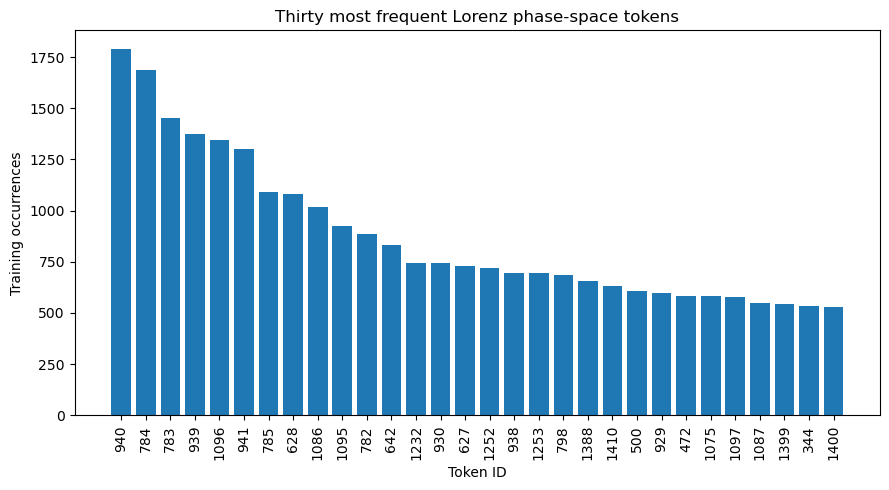

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\result images\hw6_1\step2_top30_token_frequencies.png


In [34]:
top_counts = train_counts.sort_values(
    ascending=False
).head(30)

plt.figure(figsize=(9, 5))
plt.bar(
    [str(int(token)) for token in top_counts.index],
    top_counts.values,
)

plt.xlabel("Token ID")
plt.ylabel("Training occurrences")
plt.title("Thirty most frequent Lorenz phase-space tokens")
plt.xticks(rotation=90)
plt.tight_layout()

path = RESULT_DIR / "step2_top30_token_frequencies.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", path.resolve())

# Task 3: Markov and m-gram baseline

The baseline compares

$$
m=1,2,3.
$$

For an order-$$m$$ model,

$$
P(
a_{n+1}=b
\mid
a_{n-m+1},\ldots,a_n
)
=
\frac{
\#\{(a_{n-m+1},\ldots,a_n,b)\}
}{
\#\{(a_{n-m+1},\ldots,a_n)\}
}.
$$

Counts are accumulated within books only.

Validation selects the baseline context length. The test split is evaluated only after the selection rule is fixed.

In [35]:
def load_token_books(split_name):
    books = []

    for path in sorted(
        (TOKEN_DIR / split_name).glob("book_*.csv")
    ):
        frame = pd.read_csv(path)
        books.append(
            frame["token"].to_numpy(dtype=np.int64)
        )

    return books


train_books = load_token_books("train")
validation_books = load_token_books("validation")

# Test books are intentionally not loaded yet.

CONTEXT_LENGTHS = [1, 2, 3]


def fit_ngram_models(books, max_order):
    models = {
        order: defaultdict(Counter)
        for order in range(1, max_order + 1)
    }

    unigram = Counter()

    for sequence in books:
        unigram.update(sequence.tolist())

        for order in range(1, max_order + 1):
            for i in range(order, len(sequence)):
                history = tuple(
                    int(x)
                    for x in sequence[i-order:i]
                )

                next_token = int(sequence[i])

                models[order][history][next_token] += 1

    global_mode = min(
        unigram,
        key=lambda token: (
            -unigram[token],
            token,
        ),
    )

    return models, unigram, global_mode


models, unigram, global_mode = fit_ngram_models(
    train_books,
    max(CONTEXT_LENGTHS),
)

In [36]:
def deterministic_mode(counter):
    return min(
        counter,
        key=lambda token: (
            -counter[token],
            token,
        ),
    )


def predict_with_backoff(history, requested_order):
    history = tuple(int(x) for x in history)

    for order in range(requested_order, 0, -1):
        key = history[-order:]

        if key in models[order]:
            return (
                deterministic_mode(models[order][key]),
                order,
            )

    return global_mode, 0


def evaluate_ngram(books, order):
    total = 0
    correct = 0
    exact_seen = 0

    for sequence in books:
        for i in range(order, len(sequence)):
            history = sequence[i-order:i]
            truth = int(sequence[i])

            exact_key = tuple(
                int(x)
                for x in history
            )

            if exact_key in models[order]:
                exact_seen += 1

            prediction, _ = predict_with_backoff(
                history,
                order,
            )

            correct += int(prediction == truth)
            total += 1

    return {
        "context_length_m": order,
        "evaluated_positions": total,
        "accuracy": correct / total,
        "exact_history_coverage": exact_seen / total,
        "unseen_exact_history_fraction": 1.0 - exact_seen / total,
    }


validation_records = [
    evaluate_ngram(validation_books, order)
    for order in CONTEXT_LENGTHS
]

validation_table = pd.DataFrame(validation_records)

validation_path = (
    DATA_DIR
    / "task3_markov_validation_results.csv"
)

validation_table.to_csv(
    validation_path,
    index=False,
)

print(validation_table.to_string(index=False))

 context_length_m  evaluated_positions  accuracy  exact_history_coverage  unseen_exact_history_fraction
                1                12500  0.629520                0.999280                       0.000720
                2                12490  0.700721                0.997118                       0.002882
                3                12480  0.752324                0.992468                       0.007532


In [37]:
best_validation_accuracy = validation_table[
    "accuracy"
].max()

selected_m = int(
    validation_table[
        np.isclose(
            validation_table["accuracy"],
            best_validation_accuracy,
        )
    ]["context_length_m"].min()
)

baseline_selection = {
    "selected_context_length_m": selected_m,
    "selection_rule": (
        "highest validation accuracy; "
        "smaller m breaks ties"
    ),
    "validation_accuracy": float(
        validation_table.loc[
            validation_table["context_length_m"] == selected_m,
            "accuracy",
        ].iloc[0]
    ),
}

selection_path = DATA_DIR / "task3_selected_markov_baseline.json"
selection_path.write_text(
    json.dumps(baseline_selection, indent=2),
    encoding="utf-8",
)

print("Selected baseline m =", selected_m)
print("Saved:", selection_path.resolve())

Selected baseline m = 3
Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\data\hw6_1\task3_selected_markov_baseline.json


# Final held-out baseline evaluation

The baseline model and selection rule are now fixed.

Only now is the test split loaded.

In [38]:
test_books = load_token_books("test")

test_records = [
    evaluate_ngram(test_books, order)
    for order in CONTEXT_LENGTHS
]

test_table = pd.DataFrame(test_records)

test_table["selected_by_validation"] = (
    test_table["context_length_m"]
    == selected_m
)

test_path = (
    DATA_DIR
    / "task3_markov_test_results.csv"
)

test_table.to_csv(
    test_path,
    index=False,
)

print(test_table.to_string(index=False))
print()
print("Saved:", test_path.resolve())

 context_length_m  evaluated_positions  accuracy  exact_history_coverage  unseen_exact_history_fraction  selected_by_validation
                1                12500  0.615440                0.999840                       0.000160                   False
                2                12490  0.698479                0.997998                       0.002002                   False
                3                12480  0.758173                0.994712                       0.005288                    True

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\data\hw6_1\task3_markov_test_results.csv


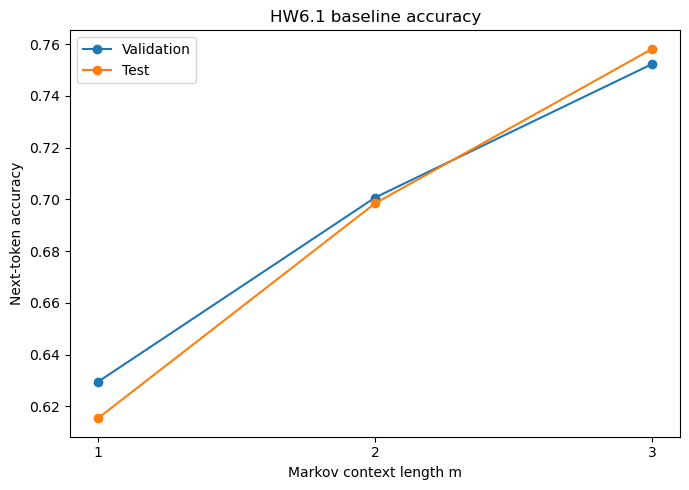

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW6.1\result images\hw6_1\step3_markov_accuracy_vs_context.png


In [39]:
plt.figure(figsize=(7, 5))

plt.plot(
    validation_table["context_length_m"],
    validation_table["accuracy"],
    marker="o",
    label="Validation",
)

plt.plot(
    test_table["context_length_m"],
    test_table["accuracy"],
    marker="o",
    label="Test",
)

plt.xlabel("Markov context length m")
plt.ylabel("Next-token accuracy")
plt.title("HW6.1 baseline accuracy")
plt.xticks(CONTEXT_LENGTHS)
plt.legend()
plt.tight_layout()

path = RESULT_DIR / "step3_markov_accuracy_vs_context.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", path.resolve())

## Steps 1-3 outputs

### Data

- `trajectory_manifest.csv`
- `token_book_manifest.csv`
- `baseline_box_vocabulary.csv`
- `baseline_configuration.json`
- `task3_markov_validation_results.csv`
- `task3_markov_test_results.csv`
- `task3_selected_markov_baseline.json`

### Result images

- `step1_example_lorenz_3d.png`
- `step2_top30_token_frequencies.png`
- `step3_markov_accuracy_vs_context.png`

The next notebook trains the causal attention predictor and compares it against this baseline.